# HR Analytics: Employee Attrition & Retention Analysis

## Project Objective:
### The main goal of this project is to analyze the factors influencing employee attrition within the organization. By exploring variables such as overtime, job satisfaction, and monthly income distribution, this project aims to uncover key drivers of turnover, identify potential retention risks, and provide data-driven insights to help HR management improve employee satisfaction and reduce turnover rates

## Dataset

The dataset used in this project was obtained from Kaggle.

**Dataset Name:** IBM HR Analytics Employee Attrition & Performance

**Source:** [Kaggle – IBM HR Analytics Dataset](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)

**Dataset Size:** 1,470 rows and 35 columns.

## Data Inspection
### First, we load the dataset and inspect its structure, columns, and data types. We also check for missing values and duplicate records to understand whether these issues need to be addressed before analysis.

In [1]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [2]:
df.shape

(1470, 35)

In [3]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')

In [4]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [6]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [7]:
df.duplicated().sum()

0

## Employee Attrition Overview
### In this section, we examine how many employees stayed and how many left the organization. We then calculate the overall attrition rate to understand the proportion of employees who left.


In [8]:
df['Attrition'].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [9]:
df['Attrition'].value_counts()['Yes'] / len(df) * 100

16.122448979591837

In [10]:
df['Attrition'].value_counts()['Yes']

237

In [11]:
len(df)

1470

## Overtime and Employee Attrition
### Here, we compare attrition between employees who work overtime and those who do not. We first review the employee counts in each group, then calculate the percentage who left within each overtime group.

In [12]:
df['OverTime'].value_counts()

OverTime
No     1054
Yes     416
Name: count, dtype: int64

In [13]:
df.groupby('OverTime')['Attrition'].value_counts()

OverTime  Attrition
No        No           944
          Yes          110
Yes       No           289
          Yes          127
Name: count, dtype: int64

In [14]:
pd.crosstab(df['OverTime'], df['Attrition'], normalize='index') * 100

Attrition,No,Yes
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


## Job Satisfaction and Employee Attrition
### This section explores the relationship between job satisfaction ratings and employee attrition. We compare the number and percentage of employees who left at each satisfaction level.

#Count Each Job Satisfaction Rating
#Purpose: See how many employees gave each job satisfaction rating.

In [15]:
df['JobSatisfaction'].value_counts()

JobSatisfaction
4    459
3    442
1    289
2    280
Name: count, dtype: int64

In [16]:
df.groupby('JobSatisfaction')['Attrition'].value_counts()

JobSatisfaction  Attrition
1                No           223
                 Yes           66
2                No           234
                 Yes           46
3                No           369
                 Yes           73
4                No           407
                 Yes           52
Name: count, dtype: int64

In [17]:
pd.crosstab(df['JobSatisfaction'], df['Attrition'], normalize='index') * 100

Attrition,No,Yes
JobSatisfaction,,
1,77.162630,22.837370
2,83.571429,16.428571
3,83.484163,16.515837
4,88.671024,11.328976


## Monthly Income Analysis
### In this section, we summarize employees' monthly income and use the Interquartile Range (IQR) method to identify potential high-income outliers. Values outside the IQR bounds are flagged for further examination; they are not automatically treated as errors or removed from the dataset.

In [18]:
df['MonthlyIncome'].describe()

count     1470.000000
mean      6502.931293
std       4707.956783
min       1009.000000
25%       2911.000000
50%       4919.000000
75%       8379.000000
max      19999.000000
Name: MonthlyIncome, dtype: float64

In [19]:
q1 = df['MonthlyIncome'].quantile(0.25)
q3 = df['MonthlyIncome'].quantile(0.75)

print(q1)
print(q3)

2911.0
8379.0


In [20]:
iqr = q3 - q1

print(iqr)

5468.0


In [21]:
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -5291.0
Upper Bound: 16581.0


In [22]:

high_income_outliers = df[df['MonthlyIncome'] > upper_bound]

print(high_income_outliers.shape[0])

114


In [23]:

high_income_outliers['MonthlyIncome'].describe()

count      114.000000
mean     18399.666667
std       1093.085190
min      16595.000000
25%      17345.750000
50%      18716.500000
75%      19376.750000
max      19999.000000
Name: MonthlyIncome, dtype: float64

In [24]:

high_income_outliers['Attrition'].value_counts()

Attrition
No     109
Yes      5
Name: count, dtype: int64

In [25]:

attrition_percentage = (
    high_income_outliers['Attrition'].value_counts(normalize=True) * 100
)

print(attrition_percentage)

Attrition
No     95.614035
Yes     4.385965
Name: proportion, dtype: float64


## Monthly Income Distribution
### The histogram visualizes how monthly income is distributed across employees. It helps us see where income values are concentrated and whether the distribution is skewed.

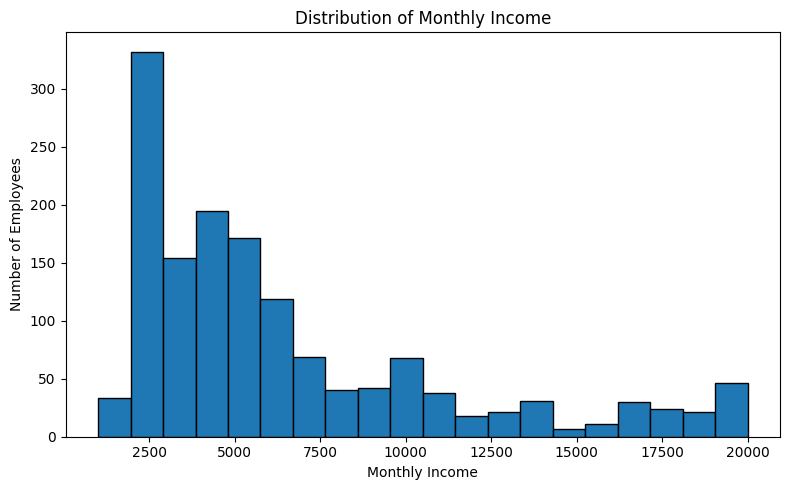

In [26]:

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.hist(df['MonthlyIncome'], bins=20, edgecolor='black')

plt.title('Distribution of Monthly Income')
plt.xlabel('Monthly Income')
plt.ylabel('Number of Employees')

plt.tight_layout()
plt.show()

#### The histogram shows that monthly income is not evenly distributed among employees. Many employees earn lower monthly salaries, while fewer employees fall into several higher-income ranges. The distribution extends toward higher salaries, indicating a right-skewed pattern.

## Employee Attrition Distribution
### This chart compares the number of employees who stayed with the organization and those who left.

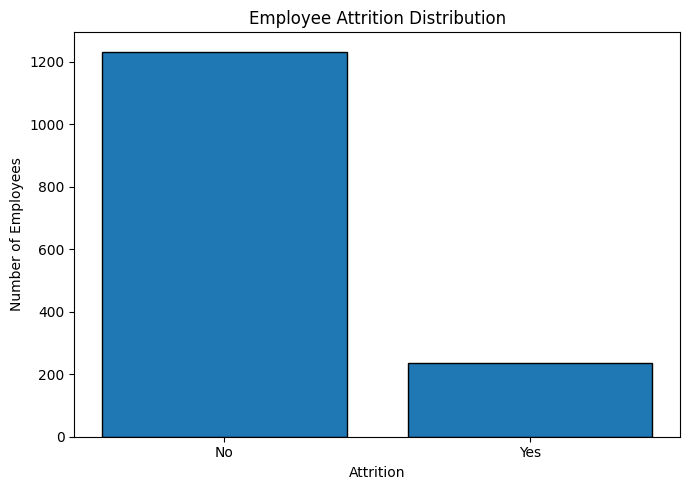

In [27]:

attrition_counts = df['Attrition'].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(attrition_counts.index, attrition_counts.values, edgecolor='black')

plt.title('Employee Attrition Distribution')
plt.xlabel('Attrition')
plt.ylabel('Number of Employees')

plt.tight_layout()
plt.show()

#### Key Findings
##### The bar chart shows that 1,233 employees (83.9%) stayed with the company, while 237 employees (16.1%) left. This indicates that employee attrition affects a smaller proportion of the workforce. The dataset also shows class imbalance, which should be considered if machine learning models are developed later.

## Overtime and Employee Attrition Visualization
### The bar chart compares the number of employees who stayed and left in each overtime group.

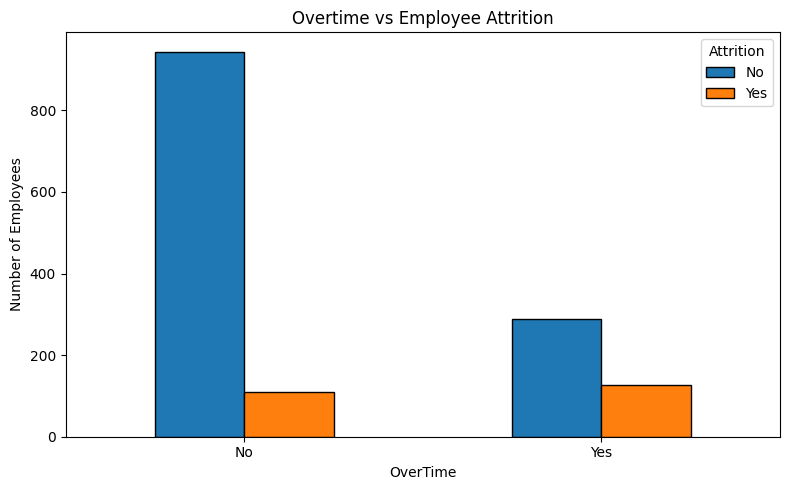

In [28]:

overtime_attrition = pd.crosstab(df['OverTime'], df['Attrition'])

overtime_attrition.plot(kind='bar', figsize=(8, 5), edgecolor='black')

plt.title('Overtime vs Employee Attrition')
plt.xlabel('OverTime')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Findings
#### The analysis shows that employees who work overtime have a higher attrition rate.
##### - Without overtime: Approximately 10.4% of employees left the company.
##### - With overtime: Approximately 30.5% of employees left the company.
#### Employees who work overtime had nearly three times the attrition rate of employees who do not work overtime. This suggests that overtime may be associated with higher employee turnover. However, this analysis shows an association and does not prove that overtime directly causes employees to leave.

## Conclusion
### The analysis identifies patterns associated with employee attrition, including differences by overtime status and job satisfaction, as well as the distribution of monthly income. These findings describe associations in this dataset and do not establish that any factor directly causes employees to leave.